In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Load data

In [2]:
DATA_DIR = Path("../data/raw")

files = sorted(DATA_DIR.glob("*.xlsx"))

print(f"Found {len(files)} Excel files:")
for file in files:
    print(f" - {file.name}")

Found 24 Excel files:
 - COPUS-form-BLAW 3430.002_10_5_26.xlsx
 - COPUS-form-BLAW 3430.002_20260921.xlsx
 - COPUS-form-BLAW 3430.004_20260922.xlsx
 - COPUS-form-BLAW3430.002 09282026.xlsx
 - COPUS-form-CHEM1410.254_9_23_2026.xlsx
 - COPUS-form-INFO5000_9_25_2026.xlsx
 - COPUS-form-INFO5307.220 08272026.xlsx
 - COPUS-form-INFO5307.221 08272026.xlsx
 - COPUS-form-INFO5307.221 09242026.xlsx
 - COPUS-form-MUMH 3510.203_20260904.xlsx
 - COPUS-form-MUMH 3510.203_20260925.xlsx
 - COPUS-form-MUMH3510-9_23_2026.xlsx
 - COPUS-form-MUMH3510.001 08312026.xlsx
 - COPUS-form-new_INFO5000_8_24_F26.xlsx
 - COPUS-form_BLAW3430.004 09222026 AKR.xlsx
 - COPUS-form_CHEM1410.254_9_16_2026.xlsx
 - COPUS-form_CHEM1410.255_9_16_2026.xlsx
 - COPUS-form_CHEM1410.255_9_23_2026.xlsx
 - COPUS-form_CHEM1410.255_9_30_2026.xlsx
 - COPUS-form_INFO5000_8_28_2026.xlsx
 - COPUS-form_INFO_5000_9_21_2026.xlsx
 - COPUS-form_MUMH3510.001 09212026-AKR.xlsx
 - COPUS-form_MUMH3510.001 10-2-2026-AKR Copy.xlsx
 - COPUS-form_MUMH3

### Batch spreadsheet structure validation

In [3]:
structure_results = []

for file in files:
    try:
        raw = pd.read_excel(file, header=None)

        code_headers = raw.iloc[8, 1:29]

        structure_results.append({
            "file": file.name,
            "rows": raw.shape[0],
            "columns": raw.shape[1],
            "code_headers_found": code_headers.notna().sum(),
            "has_expected_columns": raw.shape[1] >= 30,
            "status": "OK"
        })

    except Exception as e:
        structure_results.append({
            "file": file.name,
            "rows": None,
            "columns": None,
            "code_headers_found": None,
            "has_expected_columns": False,
            "status": str(e)
        })

structure_df = pd.DataFrame(structure_results)

display(structure_df)

print("\nFiles:", len(structure_df))
print("Read errors:", (structure_df["status"] != "OK").sum())
print(
    "Files with insufficient columns:",
    (~structure_df["has_expected_columns"]).sum()
)

,file,rows,columns,code_headers_found,has_expected_columns,status
0,COPUS-form-BLAW 3430.002_10_5_26.xlsx,59,30,28,True,OK
1,COPUS-form-BLAW 3430.002_20260921.xlsx,59,30,28,True,OK
2,COPUS-form-BLAW 3430.004_20260922.xlsx,59,30,28,True,OK
3,COPUS-form-BLAW3430.002 09282026.xlsx,46,30,28,True,OK
4,COPUS-form-CHEM1410.254_9_23_2026.xlsx,48,30,28,True,OK
5,COPUS-form-INFO5000_9_25_2026.xlsx,57,30,28,True,OK
6,COPUS-form-INFO5307.220 08272026.xlsx,58,30,28,True,OK
7,COPUS-form-INFO5307.221 08272026.xlsx,69,31,28,True,OK
8,COPUS-form-INFO5307.221 09242026.xlsx,61,30,28,True,OK
9,COPUS-form-MUMH 3510.203_20260904.xlsx,41,30,28,True,OK



Files: 24
Read errors: 0
Files with insufficient columns: 0


### Verify COPUS code-header consistency

In [4]:
reference_file = next(
    f for f in files
    if f.name == "COPUS-form-CHEM1410.254_9_23_2026.xlsx"
)

reference = pd.read_excel(reference_file, header=None)
expected_codes = reference.iloc[8, 1:29].tolist()

header_results = []

for file in files:
    raw = pd.read_excel(file, header=None)

    actual_codes = raw.iloc[8, 1:29].tolist()

    differences = [
        (i + 1, expected, actual)
        for i, (expected, actual)
        in enumerate(zip(expected_codes, actual_codes))
        if expected != actual
    ]

    header_results.append({
        "file": file.name,
        "headers_match": len(differences) == 0,
        "differences": differences
    })

header_validation = pd.DataFrame(header_results)

display(header_validation)

print(
    "Files with mismatched headers:",
    (~header_validation["headers_match"]).sum()
)

,file,headers_match,differences
0,COPUS-form-BLAW 3430.002_10_5_26.xlsx,True,[]
1,COPUS-form-BLAW 3430.002_20260921.xlsx,True,[]
2,COPUS-form-BLAW 3430.004_20260922.xlsx,True,[]
3,COPUS-form-BLAW3430.002 09282026.xlsx,True,[]
4,COPUS-form-CHEM1410.254_9_23_2026.xlsx,True,[]
5,COPUS-form-INFO5000_9_25_2026.xlsx,True,[]
6,COPUS-form-INFO5307.220 08272026.xlsx,True,[]
7,COPUS-form-INFO5307.221 08272026.xlsx,True,[]
8,COPUS-form-INFO5307.221 09242026.xlsx,True,[]
9,COPUS-form-MUMH 3510.203_20260904.xlsx,True,[]


Files with mismatched headers: 0


### Inspect metadata and COPUS columns

In [5]:
def inspect_copus_form(path):
    raw = pd.read_excel(path, header=None)

    metadata = {
        "file": path.name,
        "date": raw.iat[1, 2],
        "semester": raw.iat[1, 7],
        "instructor": raw.iat[1, 12],
        "students": raw.iat[1, 19],
        "course": f"{raw.iat[2, 7]} {raw.iat[2, 12]}",
        "observer": raw.iat[2, 19],
    }

    codes = []

    for col in range(1, 29):
        code = raw.iat[8, col]

        if pd.isna(code):
            continue

        category = (
            "student" if col <= 13
            else "instructor" if col <= 25
            else "engagement"
        )

        codes.append({
            "column": col,
            "category": category,
            "code": code,
            "variable": f"{category}_{code}"
        })

    return metadata, pd.DataFrame(codes)

In [6]:
for file in files:
    metadata, codes = inspect_copus_form(file)

    print("\n", metadata)
    display(codes)


 {'file': 'COPUS-form-BLAW 3430.002_10_5_26.xlsx', 'date': datetime.datetime(2026, 10, 5, 0, 0), 'semester': 'Fall', 'instructor': 'Adam Whitten', 'students': 65, 'course': 'BLAW  3430.002', 'observer': 'Natalie Brown'}


,column,category,code,variable
0,1,student,L,student_L
1,2,student,Ind,student_Ind
2,3,student,CG,student_CG
3,4,student,WG,student_WG
4,5,student,OG,student_OG
5,6,student,AnQ,student_AnQ
6,7,student,SQ,student_SQ
7,8,student,WC,student_WC
8,9,student,Prd,student_Prd
9,10,student,SP,student_SP



 {'file': 'COPUS-form-BLAW 3430.002_20260921.xlsx', 'date': datetime.datetime(2026, 9, 21, 0, 0), 'semester': 'Fall', 'instructor': 'Adam Whitten', 'students': 65, 'course': 'BLAW  3430.002', 'observer': 'Rainie Yu'}


,column,category,code,variable
0,1,student,L,student_L
1,2,student,Ind,student_Ind
2,3,student,CG,student_CG
3,4,student,WG,student_WG
4,5,student,OG,student_OG
5,6,student,AnQ,student_AnQ
6,7,student,SQ,student_SQ
7,8,student,WC,student_WC
8,9,student,Prd,student_Prd
9,10,student,SP,student_SP



 {'file': 'COPUS-form-BLAW 3430.004_20260922.xlsx', 'date': datetime.datetime(2026, 9, 22, 0, 0), 'semester': 'Fall', 'instructor': 'Adam Whitten', 'students': 68, 'course': 'BLAW  3430.004', 'observer': 'Rainie Yu'}


...

,column,category,code,variable
0,1,student,L,student_L
1,2,student,Ind,student_Ind
2,3,student,CG,student_CG
3,4,student,WG,student_WG
4,5,student,OG,student_OG
5,6,student,AnQ,student_AnQ
6,7,student,SQ,student_SQ
7,8,student,WC,student_WC
8,9,student,Prd,student_Prd
9,10,student,SP,student_SP



 {'file': 'COPUS-form_MUMH3510.001 10-2-2026-AKR Copy.xlsx', 'date': datetime.datetime(2026, 10, 2, 0, 0), 'semester': 'Fall', 'instructor': 'Brian Anderson', 'students': 30, 'course': 'MUNH 3510', 'observer': 'Natalie Brown'}


,column,category,code,variable
0,1,student,L,student_L
1,2,student,Ind,student_Ind
2,3,student,CG,student_CG
3,4,student,WG,student_WG
4,5,student,OG,student_OG
5,6,student,AnQ,student_AnQ
6,7,student,SQ,student_SQ
7,8,student,WC,student_WC
8,9,student,Prd,student_Prd
9,10,student,SP,student_SP



 {'file': 'COPUS-form_MUMH3510_20260902.xlsx', 'date': datetime.datetime(2026, 9, 2, 0, 0), 'semester': 'Fall', 'instructor': 'Anderson,Brian', 'students': 50, 'course': 'MUMH 3510', 'observer': 'Trebat,Thomas'}


,column,category,code,variable
0,1,student,L,student_L
1,2,student,Ind,student_Ind
2,3,student,CG,student_CG
3,4,student,WG,student_WG
4,5,student,OG,student_OG
5,6,student,AnQ,student_AnQ
6,7,student,SQ,student_SQ
7,8,student,WC,student_WC
8,9,student,Prd,student_Prd
9,10,student,SP,student_SP


### Extract observation intervals

In [7]:
def load_copus_intervals(path):
    raw = pd.read_excel(path, header=None)

    metadata, codes = inspect_copus_form(path)

    records = []

    for _, row in raw.iterrows():
        interval_label = row.iloc[0]

        if pd.isna(interval_label):
            continue

        match = re.fullmatch(
            r"\s*(\d+)(?:\s*-\s*(\d+))?\s*",
            str(interval_label)
        )

        if not match:
            continue

        start_min = int(match.group(1))
        end_min = start_min + 2

        record = {
            **metadata,
            "start_min": start_min,
            "end_min": end_min,
            "comments": row.iloc[29]
                if pd.notna(row.iloc[29]) else ""
        }

        for _, code_info in codes.iterrows():
            value = row.iloc[int(code_info["column"])]

            record[code_info["variable"]] = int(
                str(value).strip().lower() == "x"
            )

        records.append(record)

    return pd.DataFrame(records)

In [8]:
df = pd.concat(
    [load_copus_intervals(file) for file in files],
    ignore_index=True
)

print(f"Files imported: {df['file'].nunique()}")
print(f"Total intervals: {len(df)}")
print(f"Total observed minutes: {len(df) * 2}")

Files imported: 24
Total intervals: 819
Total observed minutes: 1638


### Standardize course identifiers

In [9]:
def standardize_course_id(filename):
    match = re.search(
        r"(BLAW|CHEM|INFO|MUMH)[ _-]*(\d{4})(?:\.(\d{3}))?",
        filename,
        flags=re.IGNORECASE
    )

    if not match:
        return None

    department, number, section = match.groups()

    course_id = f"{department.upper()} {number}"

    if section:
        course_id += f".{section}"

    return course_id


df["course_id"] = df["file"].apply(standardize_course_id)

In [10]:
course_validation = (
    df[["file", "course", "course_id"]]
    .drop_duplicates()
    .sort_values("course_id")
)

display(course_validation)

print(
    "Missing course IDs:",
    df["course_id"].isna().sum()
)

,file,course,course_id
0,COPUS-form-BLAW 3430.002_10_5_26.xlsx,BLAW 3430.002,BLAW 3430.002
40,COPUS-form-BLAW 3430.002_20260921.xlsx,BLAW 3430.002,BLAW 3430.002
120,COPUS-form-BLAW3430.002 09282026.xlsx,BLAW 3430,BLAW 3430.002
80,COPUS-form-BLAW 3430.004_20260922.xlsx,BLAW 3430.004,BLAW 3430.004
480,COPUS-form_BLAW3430.004 09222026 AKR.xlsx,BLAW 3430,BLAW 3430.004
150,COPUS-form-CHEM1410.254_9_23_2026.xlsx,CHEM 1410,CHEM 1410.254
519,COPUS-form_CHEM1410.254_9_16_2026.xlsx,CHEM 1410.254,CHEM 1410.254
559,COPUS-form_CHEM1410.255_9_16_2026.xlsx,CHEM 1410.255,CHEM 1410.255
599,COPUS-form_CHEM1410.255_9_23_2026.xlsx,CHEM 1410.255,CHEM 1410.255
639,COPUS-form_CHEM1410.255_9_30_2026.xlsx,CHEM 1410.255,CHEM 1410.255


Missing course IDs: 0


In [11]:
metadata_summary = (
    df.groupby("file")
    .agg(
        course=("course", "first"),
        date=("date", "first"),
        observer=("observer", "first"),
        instructor=("instructor", "first"),
        intervals=("start_min", "count")
    )
    .reset_index()
)

display(metadata_summary)

,file,course,date,observer,instructor,intervals
0,COPUS-form-BLAW 3430.002_10_5_26.xlsx,BLAW 3430.002,2026-10-05 00:00:00,Natalie Brown,Adam Whitten,40
1,COPUS-form-BLAW 3430.002_20260921.xlsx,BLAW 3430.002,2026-09-21 00:00:00,Rainie Yu,Adam Whitten,40
2,COPUS-form-BLAW 3430.004_20260922.xlsx,BLAW 3430.004,2026-09-22 00:00:00,Rainie Yu,Adam Whitten,40
3,COPUS-form-BLAW3430.002 09282026.xlsx,BLAW 3430,2026-09-28 00:00:00,Tania Heap,Adam Whitten,30
4,COPUS-form-CHEM1410.254_9_23_2026.xlsx,CHEM 1410,2026-09-23 00:00:00,"Trebat, Thomas","Petros, Amy",30
5,COPUS-form-INFO5000_9_25_2026.xlsx,INFO 5000,2026-09-25 00:00:00,"Trebat, Thomas",None,38
6,COPUS-form-INFO5307.220 08272026.xlsx,nan INFO 5307 220,2026-08-27 00:00:00,Tania Heap,Fariba Fard,38
7,COPUS-form-INFO5307.221 08272026.xlsx,INFO 5307,8272026,Tania Heap,Fariba Fard,48
8,COPUS-form-INFO5307.221 09242026.xlsx,INFO 5307 221,9242026,Tania Heap,Fariba Fard,45
9,COPUS-form-MUMH 3510.203_20260904.xlsx,MUMH 3510,2026-09-04 00:00:00,Rainie Yu,Brian Anderson,25


### Identify date inconsistencies

In [12]:
date_validation = (
    df[["file", "course_id", "date"]]
    .drop_duplicates(subset=["file"])
    .copy()
)

date_validation["date_type"] = (
    date_validation["date"]
    .apply(lambda x: type(x).__name__)
)

date_validation["date_clean"] = (
    date_validation["date"]
    .astype(str)
    .str.strip()
    .str.replace("`", "", regex=False)
)

date_validation["date_parsed"] = pd.to_datetime(
    date_validation["date_clean"],
    format="mixed",
    errors="coerce"
)

display(date_validation)

print(
    "\nUnparseable dates:",
    date_validation["date_parsed"].isna().sum()
)

,file,course_id,date,date_type,date_clean,date_parsed
0,COPUS-form-BLAW 3430.002_10_5_26.xlsx,BLAW 3430.002,2026-10-05 00:00:00,Timestamp,2026-10-05 00:00:00,2026-10-05
40,COPUS-form-BLAW 3430.002_20260921.xlsx,BLAW 3430.002,2026-09-21 00:00:00,Timestamp,2026-09-21 00:00:00,2026-09-21
80,COPUS-form-BLAW 3430.004_20260922.xlsx,BLAW 3430.004,2026-09-22 00:00:00,Timestamp,2026-09-22 00:00:00,2026-09-22
120,COPUS-form-BLAW3430.002 09282026.xlsx,BLAW 3430.002,2026-09-28 00:00:00,Timestamp,2026-09-28 00:00:00,2026-09-28
150,COPUS-form-CHEM1410.254_9_23_2026.xlsx,CHEM 1410.254,2026-09-23 00:00:00,Timestamp,2026-09-23 00:00:00,2026-09-23
180,COPUS-form-INFO5000_9_25_2026.xlsx,INFO 5000,2026-09-25 00:00:00,Timestamp,2026-09-25 00:00:00,2026-09-25
218,COPUS-form-INFO5307.220 08272026.xlsx,INFO 5307.220,2026-08-27 00:00:00,Timestamp,2026-08-27 00:00:00,2026-08-27
256,COPUS-form-INFO5307.221 08272026.xlsx,INFO 5307.221,8272026,int,8272026,NaT
304,COPUS-form-INFO5307.221 09242026.xlsx,INFO 5307.221,9242026,int,9242026,NaT
349,COPUS-form-MUMH 3510.203_20260904.xlsx,MUMH 3510.203,2026-09-04 00:00:00,Timestamp,2026-09-04 00:00:00,2026-09-04



Unparseable dates: 2


In [13]:
date_corrections = {
    "8272026": "2026-08-27",
    "9242026": "2026-09-24"
}

df["observation_date"] = (
    df["date"]
    .astype(str)
    .str.strip()
    .str.replace("`", "", regex=False)
    .replace(date_corrections)
)

df["observation_date"] = pd.to_datetime(
    df["observation_date"],
    format="mixed",
    errors="coerce"
)

In [14]:
date_summary = (
    df[["file", "course_id", "observation_date"]]
    .drop_duplicates()
    .sort_values(["course_id", "observation_date"])
)

display(date_summary)

print(
    "Missing observation dates:",
    df["observation_date"].isna().sum()
)

,file,course_id,observation_date
40,COPUS-form-BLAW 3430.002_20260921.xlsx,BLAW 3430.002,2026-09-21
120,COPUS-form-BLAW3430.002 09282026.xlsx,BLAW 3430.002,2026-09-28
0,COPUS-form-BLAW 3430.002_10_5_26.xlsx,BLAW 3430.002,2026-10-05
80,COPUS-form-BLAW 3430.004_20260922.xlsx,BLAW 3430.004,2026-09-22
480,COPUS-form_BLAW3430.004 09222026 AKR.xlsx,BLAW 3430.004,2026-09-22
519,COPUS-form_CHEM1410.254_9_16_2026.xlsx,CHEM 1410.254,2026-08-26
150,COPUS-form-CHEM1410.254_9_23_2026.xlsx,CHEM 1410.254,2026-09-23
559,COPUS-form_CHEM1410.255_9_16_2026.xlsx,CHEM 1410.255,2026-09-16
599,COPUS-form_CHEM1410.255_9_23_2026.xlsx,CHEM 1410.255,2026-09-23
639,COPUS-form_CHEM1410.255_9_30_2026.xlsx,CHEM 1410.255,2026-09-30


Missing observation dates: 0


### Check for overlapping observations

In [15]:
observation_summary = (
    df.groupby(["course_id", "observation_date", "file"])
    .agg(
        observer=("observer", "first"),
        intervals=("start_min", "count")
    )
    .reset_index()
)

overlapping_observations = observation_summary[
    observation_summary.duplicated(
        subset=["course_id", "observation_date"],
        keep=False
    )
].sort_values(["course_id", "observation_date"])

display(overlapping_observations)

print(
    "Total observation forms:",
    len(observation_summary)
)

print(
    "Unique course-date combinations:",
    observation_summary[
        ["course_id", "observation_date"]
    ].drop_duplicates().shape[0]
)

,course_id,observation_date,file,observer,intervals
3,BLAW 3430.004,2026-09-22,COPUS-form-BLAW 3430.004_20260922.xlsx,Rainie Yu,40
4,BLAW 3430.004,2026-09-22,COPUS-form_BLAW3430.004 09222026 AKR.xlsx,Amy Petros,39


Total observation forms: 24
Unique course-date combinations: 23


### Verify that all observation intervals were imported correctly

In [16]:
summary = (
    df.groupby(["file", "course"])
      .agg(
          intervals=("start_min", "count"),
          first_interval=("start_min", "min"),
          last_interval=("end_min", "max")
      )
      .reset_index()
)

display(summary)

,file,course,intervals,first_interval,last_interval
0,COPUS-form-BLAW 3430.002_10_5_26.xlsx,BLAW 3430.002,40,0,80
1,COPUS-form-BLAW 3430.002_20260921.xlsx,BLAW 3430.002,40,0,80
2,COPUS-form-BLAW 3430.004_20260922.xlsx,BLAW 3430.004,40,0,80
3,COPUS-form-BLAW3430.002 09282026.xlsx,BLAW 3430,30,0,60
4,COPUS-form-CHEM1410.254_9_23_2026.xlsx,CHEM 1410,30,0,60
5,COPUS-form-INFO5000_9_25_2026.xlsx,INFO 5000,38,0,76
6,COPUS-form-INFO5307.220 08272026.xlsx,nan INFO 5307 220,38,0,76
7,COPUS-form-INFO5307.221 08272026.xlsx,INFO 5307,48,0,96
8,COPUS-form-INFO5307.221 09242026.xlsx,INFO 5307 221,45,0,90
9,COPUS-form-MUMH 3510.203_20260904.xlsx,MUMH 3510,25,0,50


### Check for missing intervals

In [17]:
validation_results = []

for filename, group in df.groupby("file"):
    starts = group["start_min"].astype(int)

    expected = set(range(0, int(group["end_min"].max()), 2))
    observed = set(starts)

    missing = sorted(expected - observed)
    duplicates = sorted(
        starts[starts.duplicated()].tolist()
    )

    invalid_durations = (
        (group["end_min"] - group["start_min"]) != 2
    ).sum()

    validation_results.append({
        "file": filename,
        "intervals": len(group),
        "duration_min": len(group) * 2,
        "missing": missing,
        "duplicates": duplicates,
        "invalid_durations": invalid_durations,
        "valid": (
            not missing
            and not duplicates
            and invalid_durations == 0
        )
    })

interval_validation = pd.DataFrame(validation_results)

display(interval_validation)

print(
    "\nFiles requiring attention:",
    (~interval_validation["valid"]).sum()
)

,file,intervals,duration_min,missing,duplicates,invalid_durations,valid
0,COPUS-form-BLAW 3430.002_10_5_26.xlsx,40,80,[],[],0,True
1,COPUS-form-BLAW 3430.002_20260921.xlsx,40,80,[],[],0,True
2,COPUS-form-BLAW 3430.004_20260922.xlsx,40,80,[],[],0,True
3,COPUS-form-BLAW3430.002 09282026.xlsx,30,60,[],[],0,True
4,COPUS-form-CHEM1410.254_9_23_2026.xlsx,30,60,[],[],0,True
5,COPUS-form-INFO5000_9_25_2026.xlsx,38,76,[],[],0,True
6,COPUS-form-INFO5307.220 08272026.xlsx,38,76,[],[],0,True
7,COPUS-form-INFO5307.221 08272026.xlsx,48,96,[],[],0,True
8,COPUS-form-INFO5307.221 09242026.xlsx,45,90,[],[],0,True
9,COPUS-form-MUMH 3510.203_20260904.xlsx,25,50,[],[],0,True



Files requiring attention: 0


### Inspect the problematic intervals

In [18]:
problem_files = interval_validation.loc[
    ~interval_validation["valid"], "file"
]

for filename in problem_files:
    group = df[df["file"] == filename]

    print(f"\n{filename}")

    display(
        group[["start_min", "end_min"]]
        .sort_values("start_min")
        .tail(12)
        .reset_index(drop=True)
    )

### Validate COPUS activity codes

In [19]:
for file in files:
    raw = pd.read_excel(file, header=None)
    _, codes = inspect_copus_form(file)

    imported = df[df["file"] == file.name]

    results = []

    for _, code in codes.iterrows():
        variable = code["variable"]
        col = int(code["column"])

        raw_count = (
            raw.iloc[:, col]
            .astype(str)
            .str.strip()
            .str.lower()
            .eq("x")
            .sum()
        )

        imported_count = imported[variable].sum()

        results.append({
            "code": variable,
            "raw_count": raw_count,
            "imported_count": imported_count,
            "match": raw_count == imported_count
        })

    validation = pd.DataFrame(results)

    print(f"\n{file.name}")
    display(validation[~validation["match"]])

    print("All counts match:", validation["match"].all())


COPUS-form-BLAW 3430.002_10_5_26.xlsx


,code,raw_count,imported_count,match


All counts match: True

COPUS-form-BLAW 3430.002_20260921.xlsx


,code,raw_count,imported_count,match


All counts match: True

COPUS-form-BLAW 3430.004_20260922.xlsx


...

All counts match: True

COPUS-form_MUMH3510.001 10-2-2026-AKR Copy.xlsx


,code,raw_count,imported_count,match


All counts match: True

COPUS-form_MUMH3510_20260902.xlsx


,code,raw_count,imported_count,match


All counts match: True


### Check for unexpected activity markers

In [20]:
for file in files:
    raw = pd.read_excel(file, header=None)
    _, codes = inspect_copus_form(file)

    labels = raw.iloc[:, 0].astype(str)

    interval_mask = labels.str.fullmatch(
        r"\s*\d+(?:\.0+)?(?:\s*-\s*\d+(?:\.0+)?)?\s*",
        na=False
    )

    code_columns = codes["column"].astype(int).tolist()

    values = (
        raw.loc[interval_mask]
        .iloc[:, code_columns]
        .fillna("")
        .astype(str)
        .stack()
        .str.strip()
        .str.lower()
    )

    unexpected = values[~values.isin(["x", ""])]

    print(f"\n{file.name}")
    print(f"Unexpected markers: {len(unexpected)}")

    if not unexpected.empty:
        display(unexpected)


COPUS-form-BLAW 3430.002_10_5_26.xlsx
Unexpected markers: 0

COPUS-form-BLAW 3430.002_20260921.xlsx
Unexpected markers: 0

COPUS-form-BLAW 3430.004_20260922.xlsx
Unexpected markers: 0

COPUS-form-BLAW3430.002 09282026.xlsx
Unexpected markers: 0

COPUS-form-CHEM1410.254_9_23_2026.xlsx
Unexpected markers: 0

COPUS-form-INFO5000_9_25_2026.xlsx
Unexpected markers: 0

COPUS-form-INFO5307.220 08272026.xlsx
Unexpected markers: 0

COPUS-form-INFO5307.221 08272026.xlsx
Unexpected markers: 0

COPUS-form-INFO5307.221 09242026.xlsx
Unexpected markers: 0

COPUS-form-MUMH 3510.203_20260904.xlsx
Unexpected markers: 0

COPUS-form-MUMH 3510.203_20260925.xlsx
Unexpected markers: 0

COPUS-form-MUMH3510-9_23_2026.xlsx
Unexpected markers: 0

COPUS-form-MUMH3510.001 08312026.xlsx
Unexpected markers: 0

COPUS-form-new_INFO5000_8_24_F26.xlsx
Unexpected markers: 0

COPUS-form_BLAW3430.004 09222026 AKR.xlsx
Unexpected markers: 0

COPUS-form_CHEM1410.254_9_16_2026.xlsx
Unexpected markers: 0

COPUS-form_CHEM1410

### Initial code usage summary

In [21]:
code_columns = [
    col for col in df.columns
    if col.startswith((
        "student_",
        "instructor_",
        "engagement_"
    ))
]

usage = (
    df.groupby("course")[code_columns]
      .mean()
      .mul(100)
      .T
)

usage.index.name = "COPUS code"

display(usage.round(1))

course,BLAW 3430.002,BLAW 3430.004,BLAW 3430,CHEM 1410,CHEM 1410.254,CHEM 1410.255,INFO 5000,INFO 5307,INFO 5307 221,MUMH 3510,MUMH 3510,MUNH 3510,nan INFO 5307 220
COPUS code,,,,,,,,,,,,,
student_L,95.0,95.0,79.7,6.7,12.5,0.8,33.1,83.3,75.6,48.0,80.3,52.0,84.2
student_Ind,0.0,0.0,0.0,13.3,0.0,12.5,9.0,0.0,0.0,6.0,30.3,6.0,0.0
student_CG,0.0,0.0,1.4,0.0,2.5,1.7,2.3,2.1,0.0,0.0,7.9,6.0,0.0
student_WG,0.0,0.0,0.0,80.0,77.5,80.0,0.8,0.0,0.0,20.0,1.3,0.0,0.0
student_OG,0.0,0.0,0.0,0.0,7.5,2.5,30.8,0.0,0.0,2.0,17.1,34.0,0.0
student_AnQ,30.0,40.0,30.4,0.0,2.5,0.0,7.5,33.3,15.6,12.0,36.8,24.0,26.3
student_SQ,15.0,5.0,4.3,0.0,0.0,0.0,5.3,0.0,0.0,0.0,7.9,4.0,2.6
student_WC,0.0,7.5,1.4,0.0,0.0,1.7,26.3,10.4,0.0,2.0,3.9,6.0,0.0
student_Prd,0.0,0.0,0.0,0.0,0.0,0.8,0.0,0.0,0.0,0.0,19.7,0.0,0.0


### Visualize activity code usage

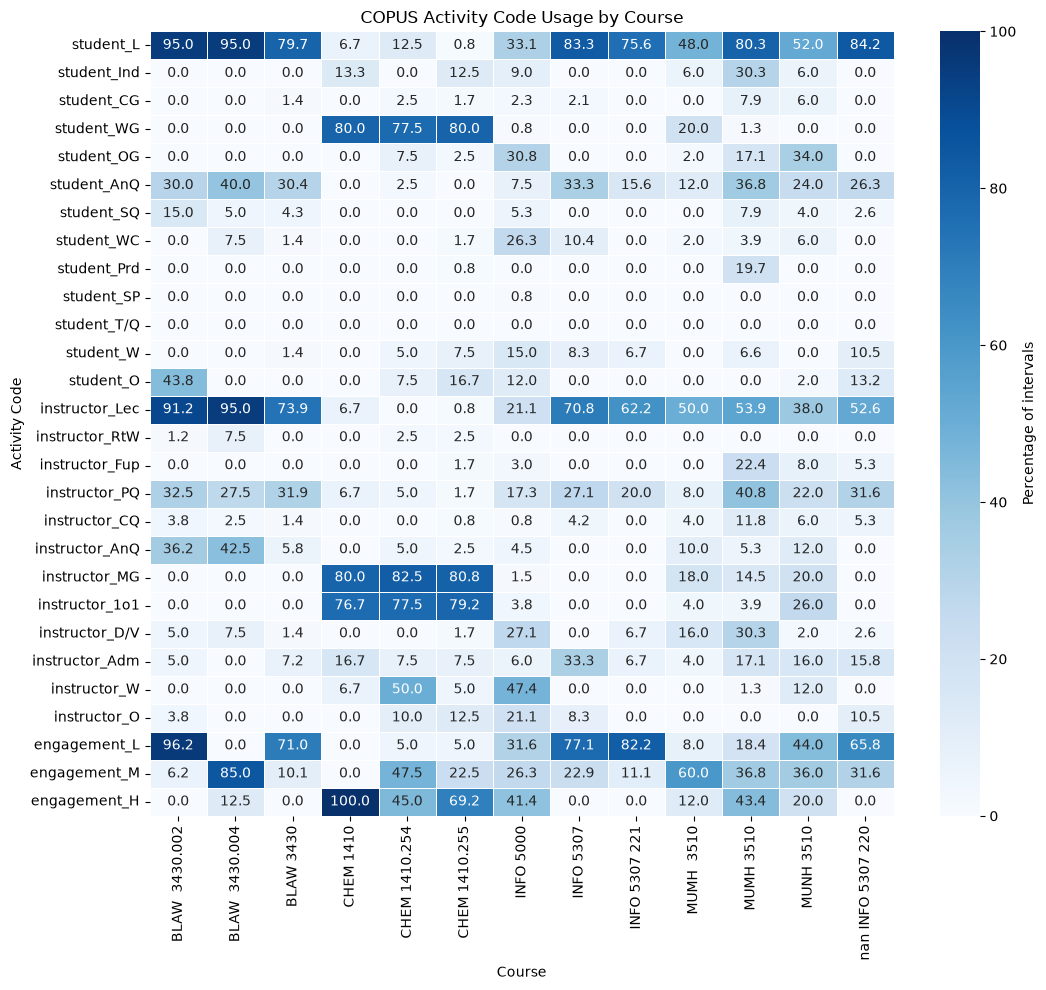

In [22]:
plt.figure(figsize=(11, 10))

sns.heatmap(
    usage,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Percentage of intervals"}
)

plt.title("COPUS Activity Code Usage by Course")
plt.xlabel("Course")
plt.ylabel("Activity Code")
plt.tight_layout()
plt.show()

### Save the validated dataset

In [23]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "copus_intervals.parquet"

text_columns = [
    "file",
    "date",
    "semester",
    "instructor",
    "students",
    "course",
    "observer",
    "comments",
    "course_id"
]

df[text_columns] = df[text_columns].astype("string")

df.to_parquet(output_path, index=False)

print(f"Saved: {output_path}")
print(f"Rows: {len(df)}")
print(f"Columns: {len(df.columns)}")
print(f"Observation forms: {df['file'].nunique()}")

Saved: ..\data\processed\copus_intervals.parquet
Rows: 819
Columns: 40
Observation forms: 24


In [24]:
df_check = pd.read_parquet(output_path)

pd.testing.assert_frame_equal(df, df_check)

print("Saved dataset verified successfully.")

Saved dataset verified successfully.
